In [ ]:
#Predicción de la amplitud de la S con los 3 s que siguen a la P. Se usan train y validación, test queda para el final.
import sys
sys.path.append('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from src.data_loader import leer_metadata, armar_split
from src.forecasting import armar_dataset, features, entrenar_cnn, predecir_cnn

df = leer_metadata()
df['split'] = armar_split(df)['split'].values
sismos = df[df['trace_category'] == 'earthquake_local']
#Se usa una muestra para que entrene en un tiempo razonable en CPU.
N_TRAIN, N_VAL = 60000, 10000
X_tr, y_tr, meta_tr = armar_dataset(sismos[sismos['split'] == 'train'].sample(N_TRAIN, random_state=0), 'dataset_train')
X_va, y_va, meta_va = armar_dataset(sismos[sismos['split'] == 'val'].sample(N_VAL, random_state=0), 'dataset_val')
X_tr.shape, X_va.shape

((44802, 3, 300), (7549, 3, 300))

## Datos

X: los 3 s desde la P de la traza filtrada, con los 3 canales, (3, 300).

y: log10 del pico en las horizontales (E y N) en los 5 s desde la S, sin filtrar.

Se descartan los sismos con la S a menos de 3 s de la P, dado que la S quedaría dentro de la ventana. A su vez se sacan los que tienen algún canal muerto.

Quedan 44802 de 60000 en train y 7549 de 10000 en validación


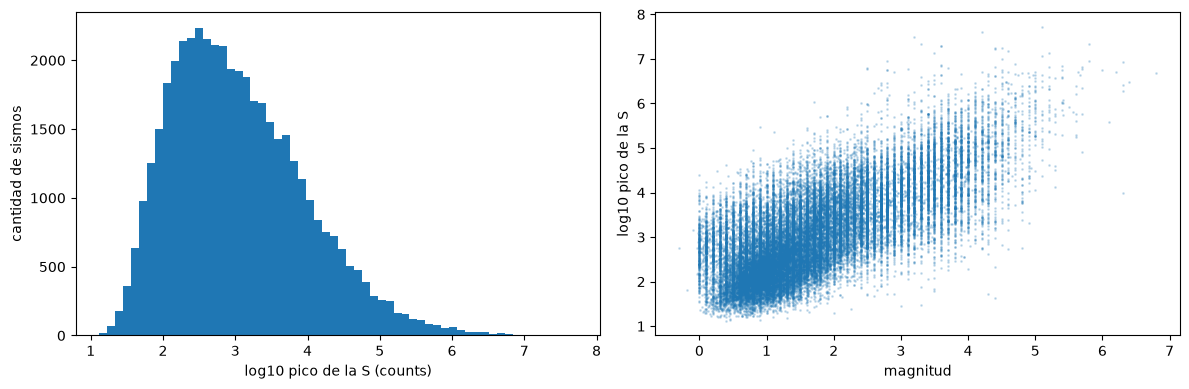

In [ ]:
print(f'Quedan {len(y_tr)} de {N_TRAIN} en train y {len(y_va)} de {N_VAL} en validación')
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].hist(y_tr, bins=60)
axs[0].set_xlabel('log10 pico de la S (counts)')
axs[0].set_ylabel('cantidad de sismos')
axs[1].scatter(meta_tr['mag'], y_tr, s=1, alpha=0.2)
axs[1].set_xlabel('magnitud')
axs[1].set_ylabel('log10 pico de la S')
plt.tight_layout()

### Regresión Lineal

Regresión lineal con 5 features de la ventana de la P: pico, RMS, Pd (pico de desplazamiento), τc (período característico) y frecuencia dominante. Como referencia se agrega predecir siempre el promedio de train, para luego compararlos.

In [ ]:
F_tr = np.array([features(w) for w in X_tr])
F_va = np.array([features(w) for w in X_va])
lineal = LinearRegression().fit(F_tr, y_tr)
pred_lin = lineal.predict(F_va)
mae_promedio = np.mean(np.abs(y_tr.mean() - y_va))
mae_lin = np.mean(np.abs(pred_lin - y_va))
print(f'Siempre el promedio: MAE {mae_promedio:.3f}')
print(f'Lineal: MAE {mae_lin:.3f}')
#Se estandarizan las features para que los coeficientes se puedan comparar entre sí.
nombres = ['pico', 'RMS', 'Pd', 'tau_c', 'frec. dominante']
coef = LinearRegression().fit((F_tr - F_tr.mean(0)) / F_tr.std(0), y_tr).coef_
pd.Series(coef, index=nombres).round(3).rename('coeficiente (features estandarizadas)')

Siempre el promedio: MAE 0.739
Lineal: MAE 0.229


pico              -0.226
RMS                1.131
Pd                -0.038
tau_c              0.034
frec. dominante    0.024
Name: coeficiente (features estandarizadas), dtype: float64

### CNN

Tres capas convolucionales sobre la forma de la ventana (dividida por su máximo), y el log10 del máximo se agrega antes de la salida, así la red no pierde la amplitud. Se entrena 20 épocas con MAE como pérdida y se guarda la época con menor error en validación en `models/cnn.pt`.

CNN: MAE 0.207, mejor época 19


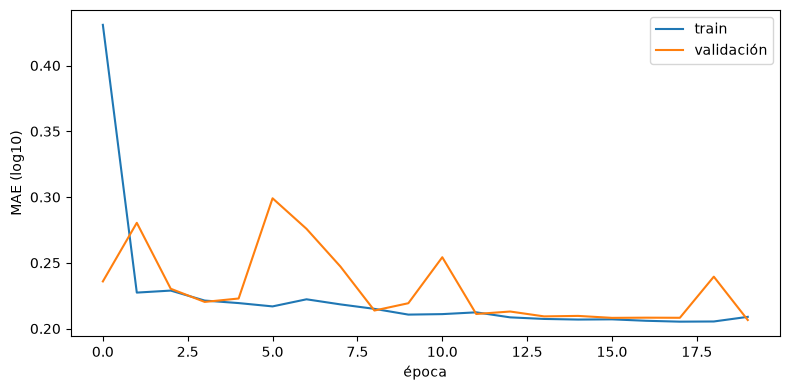

In [ ]:
cnn, historia = entrenar_cnn(X_tr, y_tr, X_va, y_va, epocas=20)
pred_cnn = predecir_cnn(cnn, X_va)
mae_cnn = np.mean(np.abs(pred_cnn - y_va))
print(f'CNN: MAE {mae_cnn:.3f}, mejor época {historia["mae_val"].idxmin()}')
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(historia['epoca'], historia['mae_train'], label='train')
ax.plot(historia['epoca'], historia['mae_val'], label='validación')
ax.set_xlabel('época')
ax.set_ylabel('MAE (log10)')
ax.legend()
plt.tight_layout()

### Comparación en validación

MAE en log10: un MAE de 0.3 quiere decir que en promedio el modelo se equivoca en un factor 10^0.3 ≈ 2.

In [5]:
pd.DataFrame({
    'MAE (log10)': [mae_promedio, mae_lin, mae_cnn],
    'factor': [10 ** mae_promedio, 10 ** mae_lin, 10 ** mae_cnn],
}, index=['promedio', 'lineal', 'CNN']).round(3)

,MAE (log10),factor
promedio,0.739,5.482
lineal,0.229,1.695
CNN,0.207,1.609


La CNN le gana a la lineal por poco: MAE 0.207 contra 0.229, o sea un factor 1.61 contra 1.70. Las dos están muy por debajo de predecir siempre el promedio (factor 5.5).

En la lineal lo que más pesa es el RMS de la ventana, es decir la amplitud de la P. El pico y el RMS están muy relacionados, por eso el pico queda con coeficiente negativo.

Con más épocas la CNN podría mejorar.